In [ ]:
import cv2
import numpy as np
import urllib.request
import os

# Download a detailed test image
image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?w=1600&q=80"
sample_file = "base_sample.jpg"

if not os.path.exists(sample_file):
    print("Downloading sample test image...")
    urllib.request.urlretrieve(image_url, sample_file)

base_img = cv2.imread(sample_file, cv2.IMREAD_GRAYSCALE)

# Resolution targets (Width, Height)
resolutions = {
    "Small": (1920, 1080),
    "Medium": (3840, 2160),
    "Large": (7680, 4320)
}

print("Preparing input datasets:")
for name, (w, h) in resolutions.items():
    resized = cv2.resize(base_img, (w, h), interpolation=cv2.INTER_CUBIC)
    bin_path = f"input_{name.lower()}.bin"
    resized.tofile(bin_path)
    file_size_mb = os.path.getsize(bin_path) / (1024 * 1024)
    print(f" • {name:6s} ({w}x{h}) -> {bin_path} ({file_size_mb:.2f} MB)")

Preparing input datasets:
 • Small  (1920x1080) -> input_small.bin (1.98 MB)
 • Medium (3840x2160) -> input_medium.bin (7.91 MB)
 • Large  (7680x4320) -> input_large.bin (31.64 MB)


In [ ]:
%%writefile sequential_sharpen.cpp
#include <iostream>
#include <vector>
#include <fstream>
#include <chrono>
#include <algorithm>

// Standard 3x3 sharpening kernel
const int KERNEL[3][3] = {
    { 0, -1,  0},
    {-1,  5, -1},
    { 0, -1,  0}
};

void sharpen_sequential(const unsigned char* input, unsigned char* output, int width, int height) {
    for (int r = 0; r < height; ++r) {
        for (int c = 0; c < width; ++c) {
            int sum = 0;

            for (int kr = -1; kr <= 1; ++kr) {
                for (int kc = -1; kc <= 1; ++kc) {
                    int nr = r + kr;
                    int nc = c + kc;

                    // Zero-padding boundary condition
                    if (nr >= 0 && nr < height && nc >= 0 && nc < width) {
                        sum += input[nr * width + nc] * KERNEL[kr + 1][kc + 1];
                    }
                }
            }

            // Clamp pixel to valid [0, 255] range
            output[r * width + c] = static_cast<unsigned char>(std::max(0, std::min(255, sum)));
        }
    }
}

int main(int argc, char* argv[]) {
    if (argc < 5) {
        std::cerr << "Usage: " << argv[0] << " <input.bin> <output.bin> <width> <height>\n";
        return 1;
    }

    std::string input_path = argv[1];
    std::string output_path = argv[2];
    int width = std::stoi(argv[3]);
    int height = std::stoi(argv[4]);
    size_t num_pixels = static_cast<size_t>(width) * height;

    std::vector<unsigned char> input(num_pixels);
    std::vector<unsigned char> output(num_pixels);

    // Read input binary buffer
    std::ifstream in_file(input_path, std::ios::binary);
    if (!in_file) {
        std::cerr << "Error opening input file: " << input_path << "\n";
        return 1;
    }
    in_file.read(reinterpret_cast<char*>(input.data()), num_pixels);
    in_file.close();

    // Compute and record execution time
    auto start = std::chrono::high_resolution_clock::now();
    sharpen_sequential(input.data(), output.data(), width, height);
    auto end = std::chrono::high_resolution_clock::now();

    std::chrono::duration<double, std::milli> duration = end - start;
    std::cout << duration.count(); // Print raw milliseconds to stdout

    // Write processed output
    std::ofstream out_file(output_path, std::ios::binary);
    out_file.write(reinterpret_cast<const char*>(output.data()), num_pixels);
    out_file.close();

    return 0;
}

Writing sequential_sharpen.cpp


In [ ]:
# Compile with standard -O3 optimization for accurate baseline profiling
!g++ -O3 sequential_sharpen.cpp -o sequential_sharpen
print("Compilation finished successfully.")

Compilation finished successfully.


In [ ]:
import subprocess
import numpy as np

configs = [
    ("Small",  1920, 1080, "input_small.bin",  "output_small.bin"),
    ("Medium", 3840, 2160, "input_medium.bin", "output_medium.bin"),
    ("Large",  7680, 4320, "input_large.bin",  "output_large.bin")
]

NUM_RUNS = 5
benchmark_results = {}

print("=" * 78)
print(f"{'Category':<10} | {'Resolution':<12} | {'Pixels':<14} | {'Avg Time (ms)':<16} | {'Runs'}")
print("=" * 78)

for category, w, h, in_file, out_file in configs:
    times = []
    for _ in range(NUM_RUNS):
        cmd = ["./sequential_sharpen", in_file, out_file, str(w), str(h)]
        result = subprocess.run(cmd, capture_output=True, text=True)
        if result.returncode == 0:
            runtime_ms = float(result.stdout.strip())
            times.append(runtime_ms)

    avg_ms = float(np.mean(times))
    benchmark_results[category] = avg_ms
    total_pixels = f"{w * h:,}"
    print(f"{category:<10} | {f'{w}x{h}':<12} | {total_pixels:<14} | {avg_ms:<16.2f} | {NUM_RUNS}")

print("=" * 78)

Category   | Resolution   | Pixels         | Avg Time (ms)    | Runs
Small      | 1920x1080    | 2,073,600      | 10.02            | 5
Medium     | 3840x2160    | 8,294,400      | 80.86            | 5
Large      | 7680x4320    | 33,177,600     | 543.37           | 5


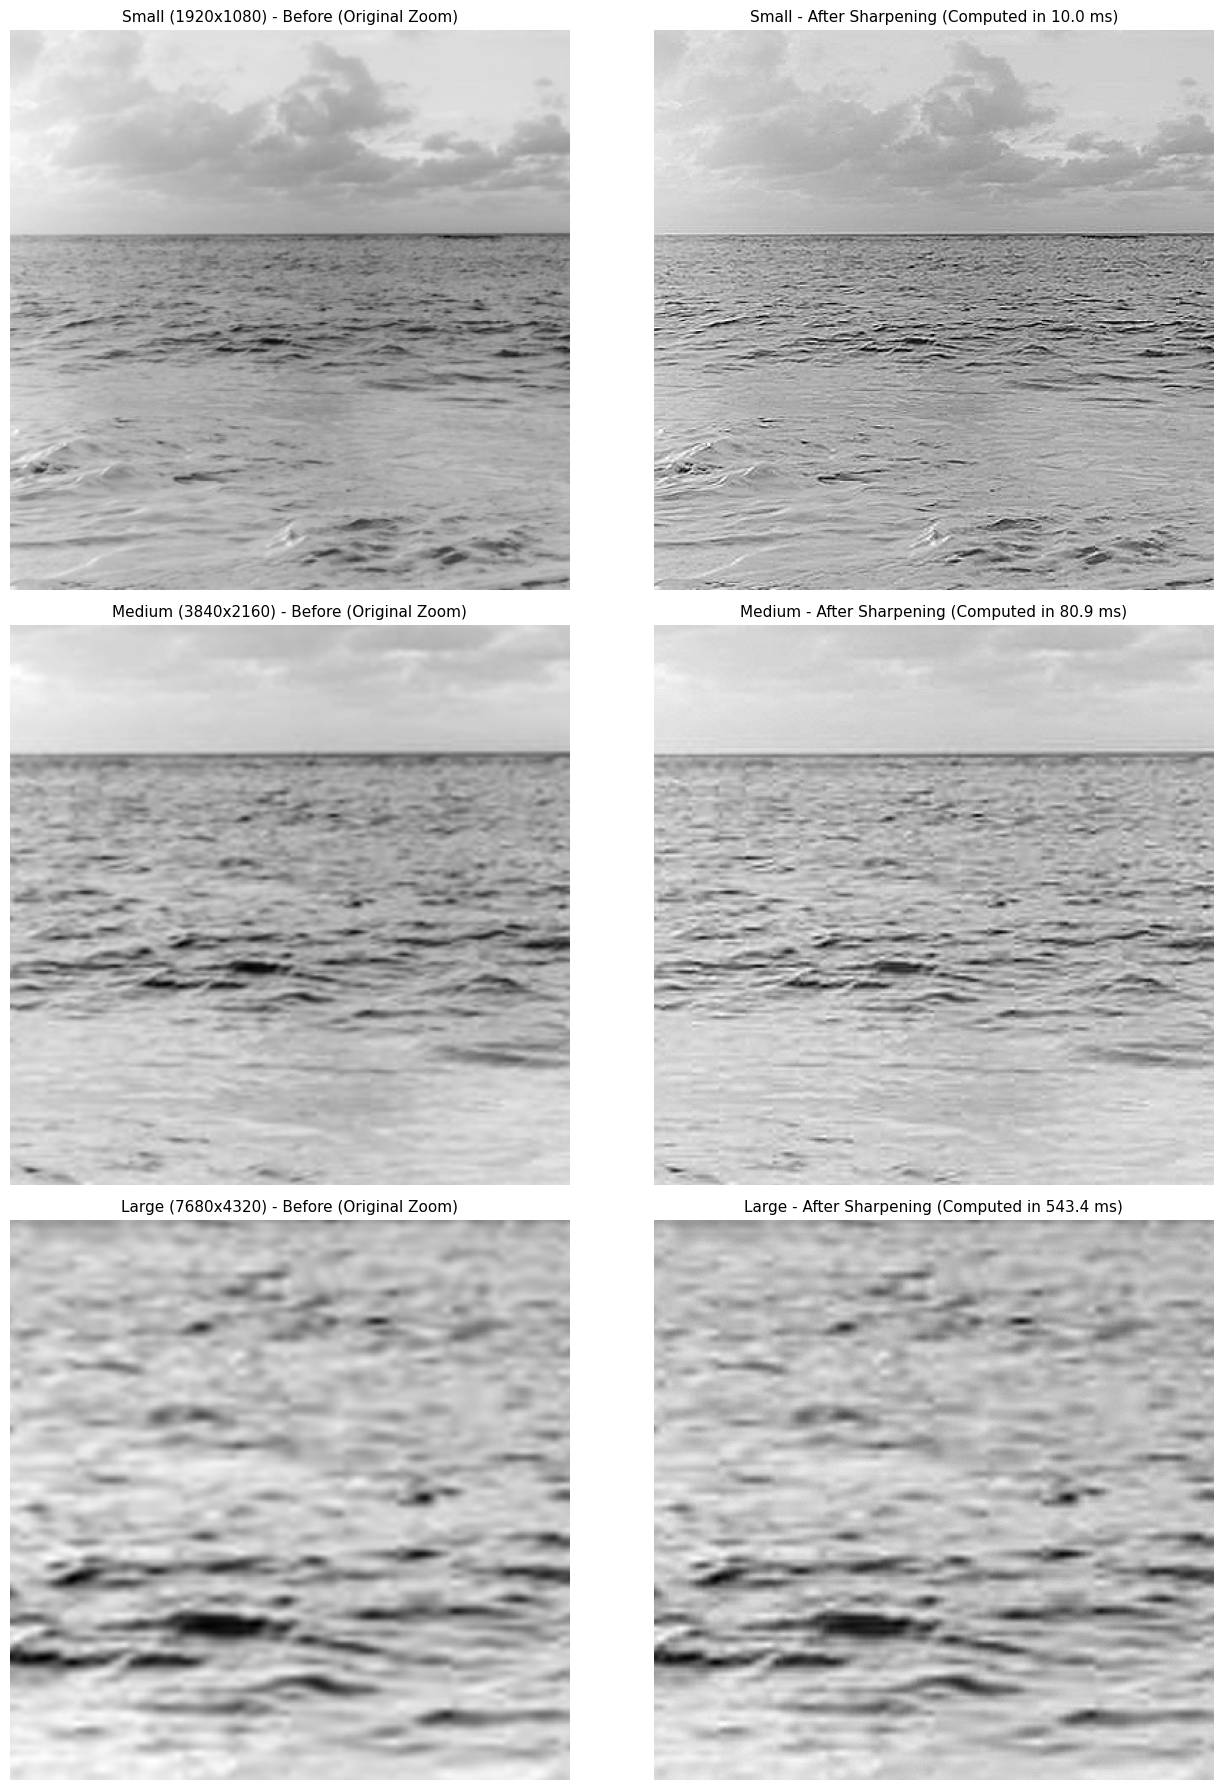

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 18))
plt.subplots_adjust(hspace=0.25)

for idx, (category, w, h, in_file, out_file) in enumerate(configs):
    # Load raw buffers
    img_before = np.fromfile(in_file, dtype=np.uint8).reshape((h, w))
    img_after = np.fromfile(out_file, dtype=np.uint8).reshape((h, w))

    # Extract a centered 400x400 zoom region to highlight edge sharpening clearly
    cy, cx = h // 2, w // 2
    crop_before = img_before[cy-200:cy+200, cx-200:cx+200]
    crop_after = img_after[cy-200:cy+200, cx-200:cx+200]

    # Plot Before
    axes[idx, 0].imshow(crop_before, cmap='gray')
    axes[idx, 0].set_title(f"{category} ({w}x{h}) - Before (Original Zoom)", fontsize=11)
    axes[idx, 0].axis('off')

    # Plot After
    ms = benchmark_results.get(category, 0.0)
    axes[idx, 1].imshow(crop_after, cmap='gray')
    axes[idx, 1].set_title(f"{category} - After Sharpening (Computed in {ms:.1f} ms)", fontsize=11)
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

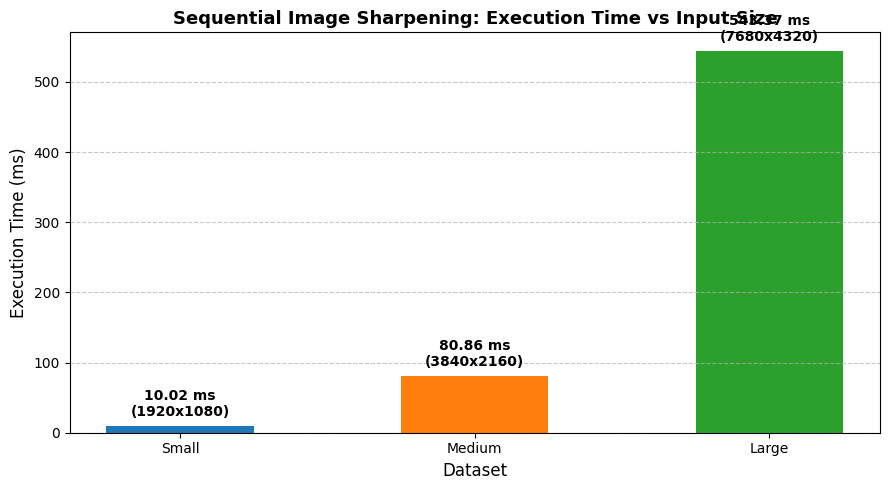

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Performance Bar Chart
labels = list(benchmark_results.keys())
times = list(benchmark_results.values())
resolutions = ["1920x1080", "3840x2160", "7680x4320"]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, times, color=['#1f77b4', '#ff7f0e', '#2ca02c'], width=0.5)

ax.set_ylabel('Execution Time (ms)', fontsize=12)
ax.set_title('Sequential Image Sharpening: Execution Time vs Input Size', fontsize=13, fontweight='bold')
ax.set_xlabel('Dataset', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.7)

for bar, res in zip(bars, resolutions):
    height = bar.get_height()
    ax.annotate(f'{height:.2f} ms\n({res})',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
import psutil
import subprocess

# --- RAM ---
ram = psutil.virtual_memory()
print(f"Total RAM: {ram.total / (1024**3):.2f} GB")
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")

# --- CPU ---
print(f"CPU Cores (Logical): {psutil.cpu_count(logical=True)}")
print(f"CPU Cores (Physical): {psutil.cpu_count(logical=False)}")

# --- GPU ---
try:
    gpu_info = subprocess.check_output(
        "nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv",
        shell=True
    ).decode('utf-8').strip().split('\n')

    print("\nGPU Status:")
    for line in gpu_info:
        print(f"  {line}")
except Exception:
    print("\nGPU Status: No GPU allocated. (Check Runtime -> Change runtime type)")

Total RAM: 12.67 GB
Available RAM: 11.40 GB
CPU Cores (Logical): 2
CPU Cores (Physical): 1

GPU Status: No GPU allocated. (Check Runtime -> Change runtime type)


##B.1  Profiling CPU Version

In [ ]:
!which perf
!perf --version

/usr/bin/perf

  You may need to install the following packages for this specific kernel:
    linux-tools-6.6.122+-6.6.122+
    linux-cloud-tools-6.6.122+-6.6.122+

  You may also want to install one of the following packages to keep up to date:
    linux-tools-6.6.122+
    linux-cloud-tools-6.6.122+


In [ ]:
!g++ -O3 -pg sequential_sharpen.cpp -o sequential_sharpen

In [ ]:
!./sequential_sharpen input_large.bin out_gprof.bin 7680 4320

181.205

In [ ]:
!ls -lh gmon.out

-rw-r--r-- 1 root root 6.1K Oct  6 19:36 gmon.out


In [ ]:
!gprof sequential_sharpen gmon.out > gprof_report.txt

In [ ]:
!head -80 gprof_report.txt

Flat profile:

Each sample counts as 0.01 seconds.
  %   cumulative   self              self     total           
 time   seconds   seconds    calls  ms/call  ms/call  name    
100.00      0.18     0.18        1   180.00   180.00  sharpen_sequential(unsigned char const*, unsigned char*, int, int)
  0.00      0.18     0.00        4     0.00     0.00  std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&)
  0.00      0.18     0.00        2     0.00     0.00  int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int)
  0.00      0.18     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::vector(unsigned long, std::allocator<unsigned char> const&)
  0.00      0.18     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::~vector()

 %       

In [ ]:
!sed -n '/Flat profile:/,/Call graph/p' gprof_report.txt

Flat profile:

Each sample counts as 0.01 seconds.
  %   cumulative   self              self     total           
 time   seconds   seconds    calls  ms/call  ms/call  name    
100.00      0.18     0.18        1   180.00   180.00  sharpen_sequential(unsigned char const*, unsigned char*, int, int)
  0.00      0.18     0.00        4     0.00     0.00  std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&)
  0.00      0.18     0.00        2     0.00     0.00  int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int)
  0.00      0.18     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::vector(unsigned long, std::allocator<unsigned char> const&)
  0.00      0.18     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::~vector()

 %       

In [ ]:
!g++ -O3 -pg sequential_sharpen.cpp -o sequential_sharpen

In [ ]:
!./sequential_sharpen input_large.bin out_gprof.bin 7680 4320

103.606

In [ ]:
!gprof sequential_sharpen gmon.out > gprof_report.txt
!sed -n '/Flat profile:/,/Call graph/p' gprof_report.txt

Flat profile:

Each sample counts as 0.01 seconds.
  %   cumulative   self              self     total           
 time   seconds   seconds    calls  ms/call  ms/call  name    
100.00      0.11     0.11        1   110.00   110.00  sharpen_sequential(unsigned char const*, unsigned char*, int, int)
  0.00      0.11     0.00        4     0.00     0.00  std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&)
  0.00      0.11     0.00        2     0.00     0.00  int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int)
  0.00      0.11     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::vector(unsigned long, std::allocator<unsigned char> const&)
  0.00      0.11     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::~vector()

 %       

In [ ]:
%%bash
BIN=./sequential_sharpen
ARGS="input_large.bin out_perf.bin 7680 4320"
PERF=$(ls /usr/lib/linux-tools/*/perf 2>/dev/null | head -1)
[ -z "$PERF" ] && PERF=$(command -v perf)

if [ -n "$PERF" ]; then
  echo "=== Performance Counter Measurements ==="
  $PERF stat -e cycles,instructions,cache-references,cache-misses $BIN $ARGS
else
  echo "perf is not available to run hardware counters."
fi

=== Performance Counter Measurements ===
257.432


 Performance counter stats for './sequential_sharpen input_large.bin out_perf.bin 7680 4320':

   <not supported>      cycles                                                                
   <not supported>      instructions                                                          
   <not supported>      cache-references                                                      
   <not supported>      cache-misses                                                          

       0.473555660 seconds time elapsed

       0.251590000 seconds user
       0.142942000 seconds sys




In [ ]:
%%bash
# Recompile without -pg profiling flags to prevent conflict with Valgrind
g++ -O3 sequential_sharpen.cpp -o sequential_sharpen

# Run Cachegrind to simulate and profile caches
echo "=== Running Cachegrind Simulation ==="
valgrind --tool=cachegrind --cachegrind-out-file=cachegrind.out ./sequential_sharpen input_large.bin out_cache.bin 7680 4320


=== Running Cachegrind Simulation ===
2663.24

==9807== Cachegrind, a high-precision tracing profiler
==9807== Copyright (C) 2002-2017, and GNU GPL'd, by Nicholas Nethercote et al.
==9807== Using Valgrind-3.22.0 and LibVEX; rerun with -h for copyright info
==9807== Command: ./sequential_sharpen input_large.bin out_cache.bin 7680 4320
==9807== 
==9807== 
==9807== I refs:        1,196,300,543


In [ ]:
%%bash
# Annotate the results of the Cachegrind run to show Cache Miss rates and instruction details
echo "=== Cachegrind Profiling Summary ==="
cg_annotate cachegrind.out | head -25

=== Cachegrind Profiling Summary ===
--------------------------------------------------------------------------------
-- Metadata
--------------------------------------------------------------------------------
Invocation:       /usr/bin/cg_annotate cachegrind.out
Command:          ./sequential_sharpen input_large.bin out_cache.bin 7680 4320
Events recorded:  Ir
Events shown:     Ir
Event sort order: Ir
Threshold:        0.1%
Annotation:       on

--------------------------------------------------------------------------------
-- Summary
--------------------------------------------------------------------------------
Ir____________________ 

1,196,300,543 (100.0%)  PROGRAM TOTALS

--------------------------------------------------------------------------------
-- File:function summary
--------------------------------------------------------------------------------
  Ir__________________________  file:function

< 1,128,017,916 (94.3%, 94.3%)  ???:
  1,127,986,723 (94.3%)           sharp

In [ ]:
%%bash
# Run Cachegrind with explicit cache simulation enabled
valgrind --tool=cachegrind --cache-sim=yes --cachegrind-out-file=cachegrind_sim.out ./sequential_sharpen input_large.bin out_cache.bin 7680 4320 > /dev/null

# Annotate results showing both instruction references and data cache references/misses
echo "=== Cachegrind Complete Cache Analysis ==="
cg_annotate cachegrind_sim.out | head -30

=== Cachegrind Complete Cache Analysis ===
--------------------------------------------------------------------------------
-- Metadata
--------------------------------------------------------------------------------
Invocation:       /usr/bin/cg_annotate cachegrind_sim.out
I1 cache:         32768 B, 64 B, 8-way associative
D1 cache:         32768 B, 64 B, 8-way associative
LL cache:         58720256 B, 64 B, 28-way associative
Command:          ./sequential_sharpen input_large.bin out_cache.bin 7680 4320
Events recorded:  Ir I1mr ILmr Dr D1mr DLmr Dw D1mw DLmw
Events shown:     Ir I1mr ILmr Dr D1mr DLmr Dw D1mw DLmw
Event sort order: Ir I1mr ILmr Dr D1mr DLmr Dw D1mw DLmw
Threshold:        0.1%
Annotation:       on

--------------------------------------------------------------------------------
-- Summary
--------------------------------------------------------------------------------
Ir____________________ I1mr__________ ILmr__________ Dr__________________ D1mr____________ DLmr_____

==10024== Cachegrind, a high-precision tracing profiler
==10024== Copyright (C) 2002-2017, and GNU GPL'd, by Nicholas Nethercote et al.
==10024== Using Valgrind-3.22.0 and LibVEX; rerun with -h for copyright info
==10024== Command: ./sequential_sharpen input_large.bin out_cache.bin 7680 4320
==10024== 
--10024-- warning: L3 cache found, using its data for the LL simulation.
--10024-- warning: specified LL cache: line_size 64  assoc 20  total_size 57,671,680
--10024-- warning: simulated LL cache: line_size 64  assoc 28  total_size 58,720,256
==10024== 
==10024== I refs:        1,196,300,643
==10024== I1  misses:            2,679
==10024== LLi misses:            2,631
==10024== I1  miss rate:          0.00%
==10024== LLi miss rate:          0.00%
==10024== 
==10024== D refs:          299,273,518  (199,555,254 rd   + 99,718,264 wr)
==10024== D1  misses:        2,090,197  (    532,602 rd   +  1,557,595 wr)
==10024== LLd misses:        1,679,193  (    526,781 rd   +  1,152,412 wr)
==10024==

In [ ]:
%%bash
BIN=./sequential_sharpen        # <-- change per notebook
ARGS="input_large.bin out_perf.bin 7680 4320"

echo "=== Environment ==="
echo "Kernel: $(uname -r)"
echo "perf_event_paranoid = $(cat /proc/sys/kernel/perf_event_paranoid 2>&1)"
echo "--- RAPL powercap sysfs ---"
ls /sys/class/powercap/ 2>&1
cat /sys/class/powercap/intel-rapl:0/energy_uj 2>&1
echo "--- perf PMUs exposed to this VM ---"
ls /sys/bus/event_source/devices/ 2>&1
ls /sys/bus/event_source/devices/power/events 2>&1

echo "=== Installing perf ==="
apt-get -qq update > /dev/null 2>&1
apt-get -qq install -y linux-tools-common linux-tools-generic > /dev/null 2>&1
apt-get -qq install -y linux-tools-$(uname -r) 2>&1 | tail -2
PERF=$(ls /usr/lib/linux-tools/*/perf 2>/dev/null | head -1)
[ -z "$PERF" ] && PERF=$(command -v perf)
echo "perf binary used: ${PERF:-NONE}"

if [ -n "$PERF" ]; then
  echo "=== B.3 attempt: perf stat RAPL energy ==="
  $PERF stat -e power/energy-pkg/,power/energy-ram/ $BIN $ARGS 2>&1 | tail -12
  echo; echo "=== B.1 attempt: perf record hotspots ==="
  $PERF record -e cpu-clock -F 999 -g -o perf.data $BIN $ARGS 2>&1 | tail -5
  $PERF report -i perf.data --stdio --sort symbol 2>&1 | grep -v '^$' | head -40
else
  echo "perf could not be installed for kernel $(uname -r) -> using gprof fallback (cell A2)"
fi


=== Environment ===
Kernel: 6.6.122+
perf_event_paranoid = 2
--- RAPL powercap sysfs ---
cat: '/sys/class/powercap/intel-rapl:0/energy_uj': No such file or directory
--- perf PMUs exposed to this VM ---
breakpoint
kprobe
msr
power
software
tracepoint
uprobe
=== Installing perf ===
E: Couldn't find any package by glob 'linux-tools-6.6.122'
E: Couldn't find any package by regex 'linux-tools-6.6.122'
perf binary used: /usr/lib/linux-tools/6.8.0-146-generic/perf
=== B.3 attempt: perf stat RAPL energy ===
Unable to find PMU or event on a PMU of 'power'

Initial error:
event syntax error: 'power/energy-pkg/,power/energy-ram/'
                           \___ unknown term 'energy-pkg' for pmu 'power'

valid terms: event,config,config1,config2,config3,name,period,percore,metric-id
Run 'perf list' for a list of valid events

 Usage: perf stat [<options>] [<command>]

    -e, --event <event>   event selector. use 'perf list' to list available events

=== B.1 attempt: perf record hotspots ===
Chec